# Práctica Deep Learning – Redes GAN
**Estudiante:** Ruby Dayana Cárdenas Gómez · **Docente:** Paul Alexander Díaz Montaña
Inteligencia Artificial – Conceptos (Semana 11)

**Objetivo:** entrenar dos redes generativas adversarias sobre Fashion-MNIST y comparar:
1. **GAN sencilla (densa / MLP)**, como la propuesta original de Goodfellow et al. (2014).
2. **DCGAN (convolucional)**, siguiendo a Radford et al. (2016).

Ambas usan los mismos datos, la misma dimensión latente, el mismo optimizador y el mismo número de épocas, para que la diferencia se deba a la arquitectura.

In [1]:
import os, time, gzip, json
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
SEED = 42
tf.keras.utils.set_random_seed(SEED)
os.makedirs('fig', exist_ok=True)
print('TensorFlow', tf.__version__)

I0000 00:00:1793931873.589103     245 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793931873.618723     245 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793931874.486066     245 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Datos: Fashion-MNIST
70.000 imágenes 28×28 en escala de grises de 10 tipos de prendas (Xiao et al., 2017). Solo se usan las 60.000 de entrenamiento para la GAN; las 10.000 de prueba se usan para evaluar.

(60000, 28, 28, 1) (10000, 28, 28, 1) -1.0 1.0


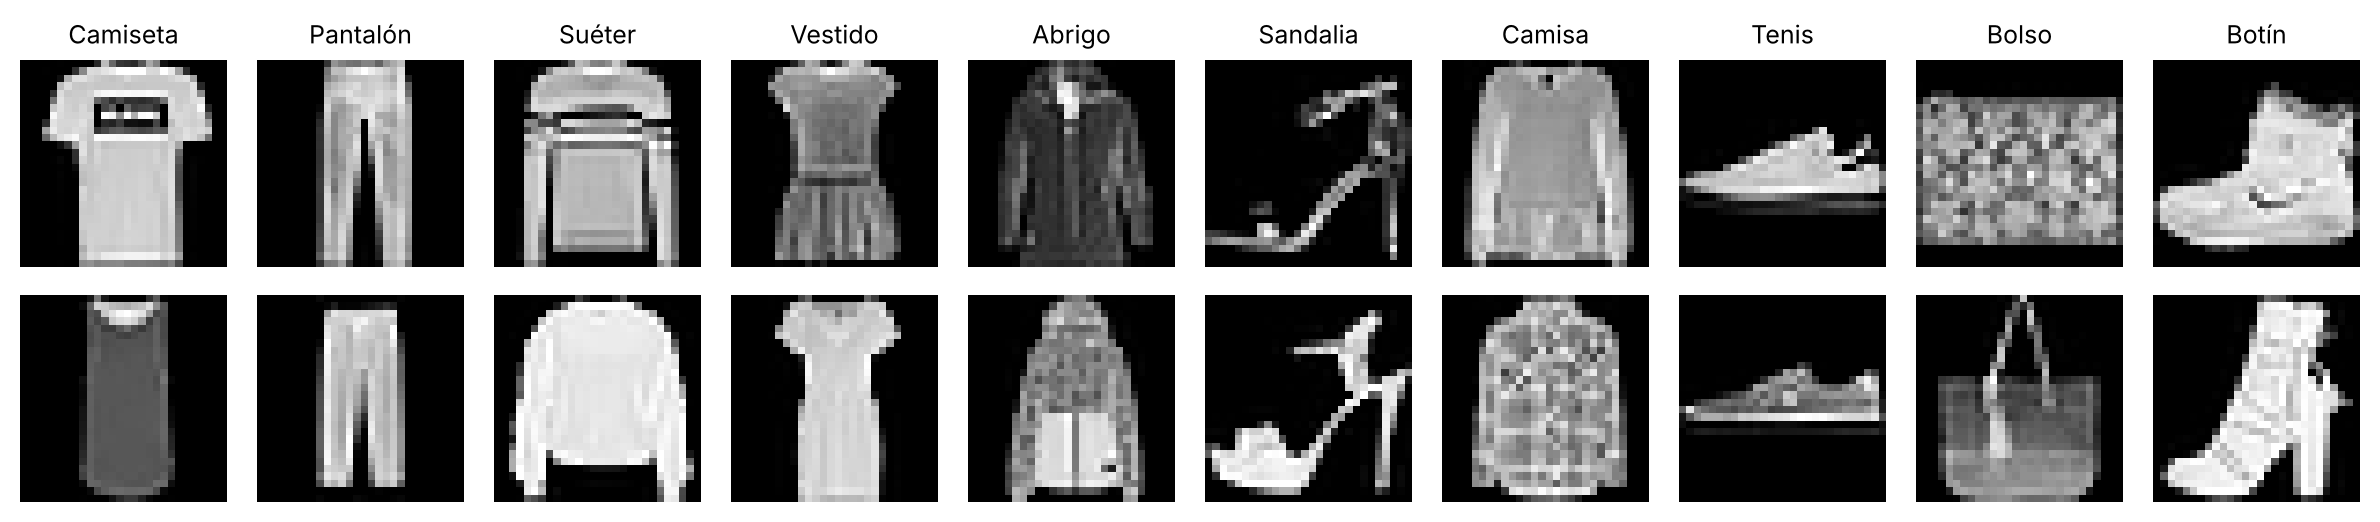

In [2]:
CLASES = ['Camiseta','Pantalón','Suéter','Vestido','Abrigo','Sandalia','Camisa','Tenis','Bolso','Botín']
def cargar_local(d):
    def img(f):
        with gzip.open(f) as fh: return np.frombuffer(fh.read(), np.uint8, offset=16).reshape(-1,28,28)
    def lab(f):
        with gzip.open(f) as fh: return np.frombuffer(fh.read(), np.uint8, offset=8)
    return ((img(f'{d}/train-images-idx3-ubyte.gz'), lab(f'{d}/train-labels-idx1-ubyte.gz')),
            (img(f'{d}/t10k-images-idx3-ubyte.gz'), lab(f'{d}/t10k-labels-idx1-ubyte.gz')))
if os.path.exists('data/train-images-idx3-ubyte.gz'):
    (x_train, y_train), (x_test, y_test) = cargar_local('data')
else:  # en Google Colab
    (x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train = (x_train.astype('float32') - 127.5) / 127.5   # escala [-1, 1] para usar tanh
x_test  = (x_test.astype('float32')  - 127.5) / 127.5
x_train = x_train[..., None]; x_test = x_test[..., None]
print(x_train.shape, x_test.shape, x_train.min(), x_train.max())

fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))
for c in range(10):
    idx = np.where(y_train == c)[0][:2]
    for r in range(2):
        ax[r, c].imshow(x_train[idx[r], :, :, 0], cmap='gray'); ax[r, c].axis('off')
    ax[0, c].set_title(CLASES[c], fontsize=9)
plt.tight_layout(); plt.savefig('fig/f_reales.png', dpi=200); plt.show()

## 2. Arquitecturas
**Generador:** recibe ruido $z\in\mathbb{R}^{100}$ y produce una imagen 28×28. **Discriminador:** recibe una imagen y devuelve un *logit* (real vs. falsa).

In [3]:
ZDIM = 100
def gen_mlp():
    return keras.Sequential([layers.Input((ZDIM,)),
        layers.Dense(256), layers.LeakyReLU(0.2), layers.BatchNormalization(),
        layers.Dense(512), layers.LeakyReLU(0.2), layers.BatchNormalization(),
        layers.Dense(1024), layers.LeakyReLU(0.2), layers.BatchNormalization(),
        layers.Dense(784, activation='tanh'), layers.Reshape((28, 28, 1))], name='G_MLP')
def disc_mlp():
    return keras.Sequential([layers.Input((28, 28, 1)), layers.Flatten(),
        layers.Dense(512), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Dense(256), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Dense(1)], name='D_MLP')
def gen_dcgan():
    return keras.Sequential([layers.Input((ZDIM,)),
        layers.Dense(7*7*256, use_bias=False), layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Reshape((7, 7, 256)),
        layers.Conv2DTranspose(128, 5, 1, 'same', use_bias=False), layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(64, 5, 2, 'same', use_bias=False), layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(1, 5, 2, 'same', activation='tanh')], name='G_DCGAN')
def disc_dcgan():
    return keras.Sequential([layers.Input((28, 28, 1)),
        layers.Conv2D(64, 5, 2, 'same'), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Conv2D(128, 5, 2, 'same'), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Flatten(), layers.Dense(1)], name='D_DCGAN')
for f in [gen_mlp, disc_mlp, gen_dcgan, disc_dcgan]:
    m = f(); print(f'{m.name:10s} parámetros: {m.count_params():,}')

G_MLP      parámetros: 1,493,520
D_MLP      parámetros: 533,505
G_DCGAN    parámetros: 2,330,945
D_DCGAN    parámetros: 212,865


## 3. Entrenamiento adversarial
En cada paso: (1) el discriminador aprende a separar reales (etiqueta 1) de falsas (0); (2) el generador aprende a que el discriminador marque sus falsas como reales. Pérdida: entropía cruzada binaria; optimizador Adam (lr = 0,0002; β₁ = 0,5).

In [4]:
EPOCHS, BATCH = 10, 128
bce = keras.losses.BinaryCrossentropy(from_logits=True)
ds = tf.data.Dataset.from_tensor_slices(x_train).shuffle(60000, seed=SEED).batch(BATCH, drop_remainder=True).prefetch(2)
z_fijo = tf.random.normal((40, ZDIM), seed=SEED)   # mismo ruido para ver la evolución

def entrenar(G, D, nombre):
    optG = keras.optimizers.Adam(2e-4, beta_1=0.5); optD = keras.optimizers.Adam(2e-4, beta_1=0.5)
    @tf.function
    def paso(real):
        z = tf.random.normal((tf.shape(real)[0], ZDIM))
        with tf.GradientTape() as tg, tf.GradientTape() as td:
            falsa = G(z, training=True)
            dr = D(real, training=True); df = D(falsa, training=True)
            lossD = bce(tf.ones_like(dr), dr) + bce(tf.zeros_like(df), df)
            lossG = bce(tf.ones_like(df), df)
        optD.apply_gradients(zip(td.gradient(lossD, D.trainable_variables), D.trainable_variables))
        optG.apply_gradients(zip(tg.gradient(lossG, G.trainable_variables), G.trainable_variables))
        return lossD, lossG, tf.reduce_mean(tf.sigmoid(dr)), tf.reduce_mean(tf.sigmoid(df))
    hist, snaps, t0 = [], {}, time.time()
    for ep in range(1, EPOCHS + 1):
        m = np.mean([[float(v) for v in paso(b)] for b in ds], 0)
        hist.append([ep, *m, time.time() - t0])
        if ep in (1, 3, 5, 10) or ep == EPOCHS:
            snaps[ep] = G(z_fijo, training=False).numpy()
        print(f'{nombre} época {ep:2d} | loss_D={m[0]:.3f} loss_G={m[1]:.3f} D(x)={m[2]:.2f} D(G(z))={m[3]:.2f} | {time.time()-t0:.0f} s', flush=True)
    return np.array(hist), snaps

In [5]:
G1, D1 = gen_mlp(), disc_mlp()
hist_mlp, snaps_mlp = entrenar(G1, D1, 'GAN-MLP')

GAN-MLP época  1 | loss_D=0.660 loss_G=2.080 D(x)=0.81 D(G(z))=0.25 | 9 s


GAN-MLP época  2 | loss_D=1.241 loss_G=0.817 D(x)=0.59 D(G(z))=0.46 | 19 s


GAN-MLP época  3 | loss_D=1.277 loss_G=0.805 D(x)=0.57 D(G(z))=0.47 | 29 s


GAN-MLP época  4 | loss_D=1.272 loss_G=0.823 D(x)=0.56 D(G(z))=0.46 | 36 s


GAN-MLP época  5 | loss_D=1.293 loss_G=0.813 D(x)=0.55 D(G(z))=0.46 | 47 s


GAN-MLP época  6 | loss_D=1.312 loss_G=0.798 D(x)=0.54 D(G(z))=0.47 | 53 s


GAN-MLP época  7 | loss_D=1.310 loss_G=0.800 D(x)=0.54 D(G(z))=0.46 | 60 s


GAN-MLP época  8 | loss_D=1.309 loss_G=0.805 D(x)=0.54 D(G(z))=0.46 | 67 s


GAN-MLP época  9 | loss_D=1.328 loss_G=0.788 D(x)=0.53 D(G(z))=0.47 | 74 s


GAN-MLP época 10 | loss_D=1.331 loss_G=0.781 D(x)=0.53 D(G(z))=0.47 | 80 s


In [6]:
G2, D2 = gen_dcgan(), disc_dcgan()
hist_dc, snaps_dc = entrenar(G2, D2, 'DCGAN')

E0000 00:00:1793931958.896878     245 meta_optimizer.cc:967] remapper failed: INVALID_ARGUMENT: Mutation::Apply error: fanout 'gradient_tape/D_DCGAN_1/leaky_re_lu_18_1/LeakyRelu/LeakyReluGrad' exist for missing node 'D_DCGAN_1/conv2d_2_1/BiasAdd'.


DCGAN época  1 | loss_D=1.317 loss_G=0.732 D(x)=0.55 D(G(z))=0.49 | 102 s


DCGAN época  2 | loss_D=1.306 loss_G=0.767 D(x)=0.53 D(G(z))=0.47 | 201 s


DCGAN época  3 | loss_D=1.224 loss_G=0.845 D(x)=0.55 D(G(z))=0.44 | 300 s


DCGAN época  4 | loss_D=1.273 loss_G=0.823 D(x)=0.54 D(G(z))=0.45 | 400 s


DCGAN época  5 | loss_D=1.314 loss_G=0.776 D(x)=0.53 D(G(z))=0.47 | 500 s


DCGAN época  6 | loss_D=1.310 loss_G=0.774 D(x)=0.53 D(G(z))=0.47 | 602 s


DCGAN época  7 | loss_D=1.308 loss_G=0.776 D(x)=0.53 D(G(z))=0.47 | 743 s


DCGAN época  8 | loss_D=1.319 loss_G=0.770 D(x)=0.53 D(G(z))=0.47 | 843 s


DCGAN época  9 | loss_D=1.320 loss_G=0.769 D(x)=0.53 D(G(z))=0.47 | 985 s


DCGAN época 10 | loss_D=1.322 loss_G=0.768 D(x)=0.53 D(G(z))=0.47 | 1127 s


## 4. Curvas de entrenamiento

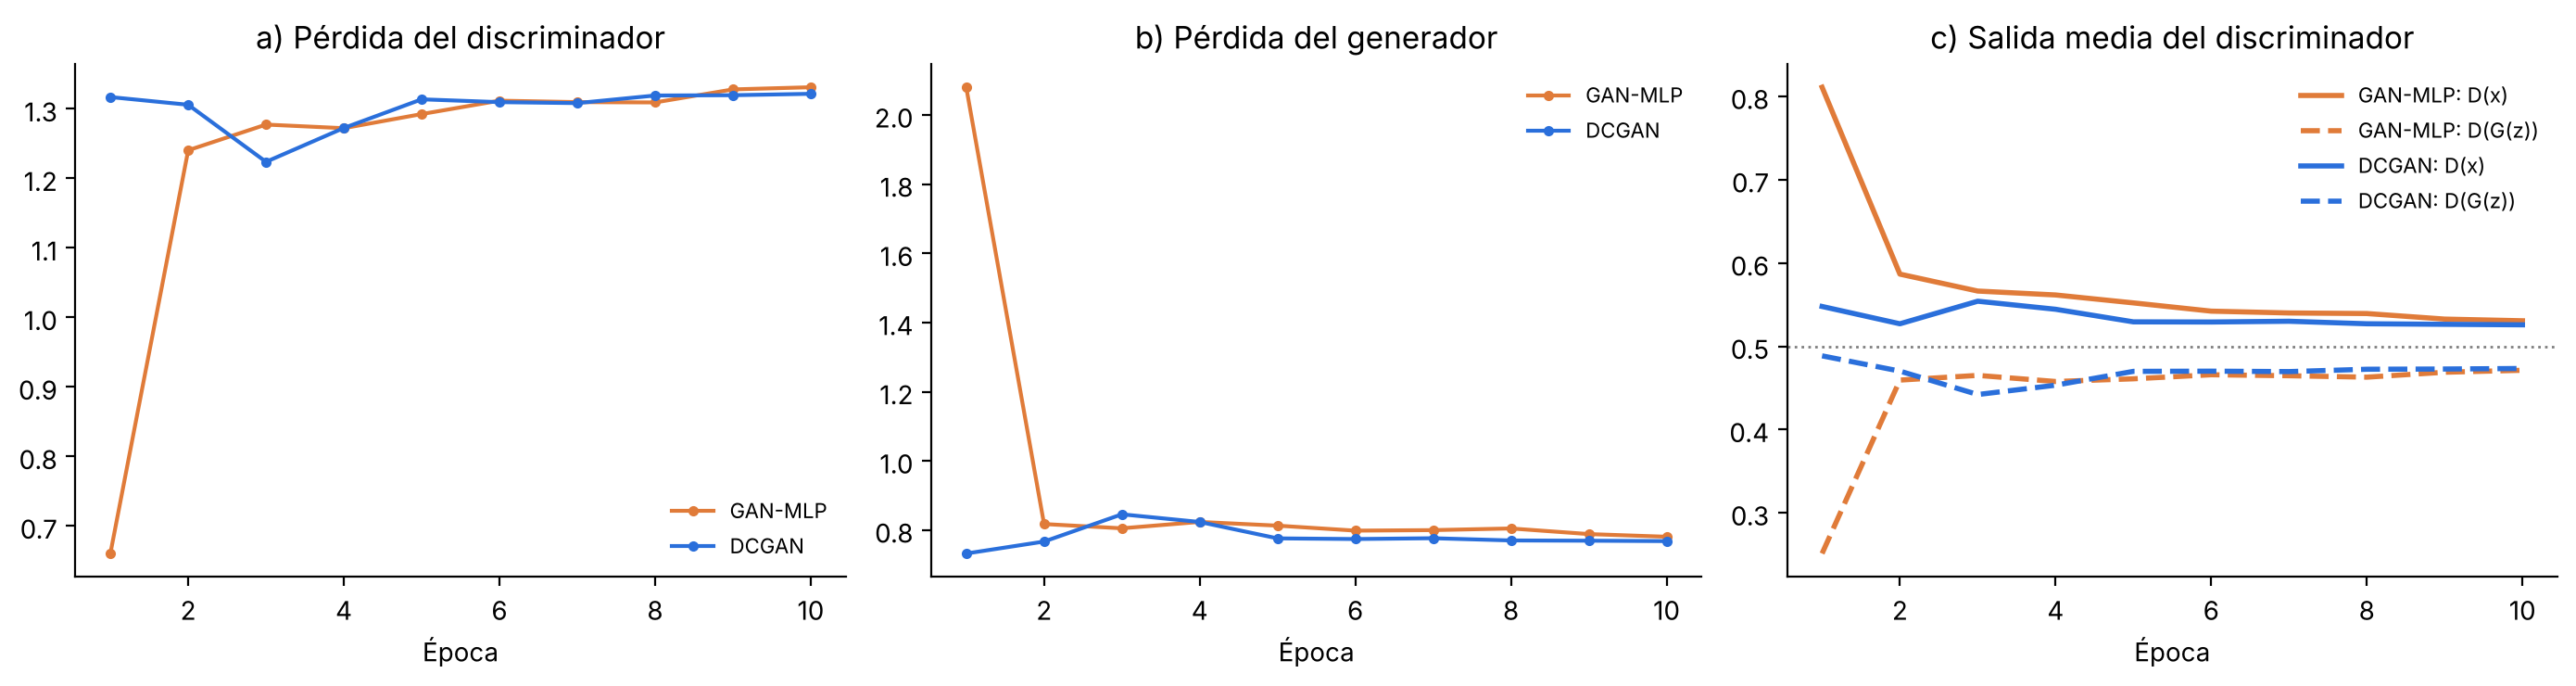

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for h, n, c in [(hist_mlp, 'GAN-MLP', '#e07b39'), (hist_dc, 'DCGAN', '#2a6fdb')]:
    ax[0].plot(h[:,0], h[:,1], color=c, marker='o', ms=3, label=n)
    ax[1].plot(h[:,0], h[:,2], color=c, marker='o', ms=3, label=n)
    ax[2].plot(h[:,0], h[:,3], color=c, lw=2, label=f'{n}: D(x)')
    ax[2].plot(h[:,0], h[:,4], color=c, lw=2, ls='--', label=f'{n}: D(G(z))')
ax[0].set_title('a) Pérdida del discriminador'); ax[1].set_title('b) Pérdida del generador'); ax[2].set_title('c) Salida media del discriminador')
ax[2].axhline(0.5, color='gray', lw=1, ls=':')
for a in ax: a.set_xlabel('Época'); a.legend(frameon=False, fontsize=8); a.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig/f_curvas.png', dpi=200); plt.show()

## 5. Evolución de las imágenes generadas (mismo ruido fijo)

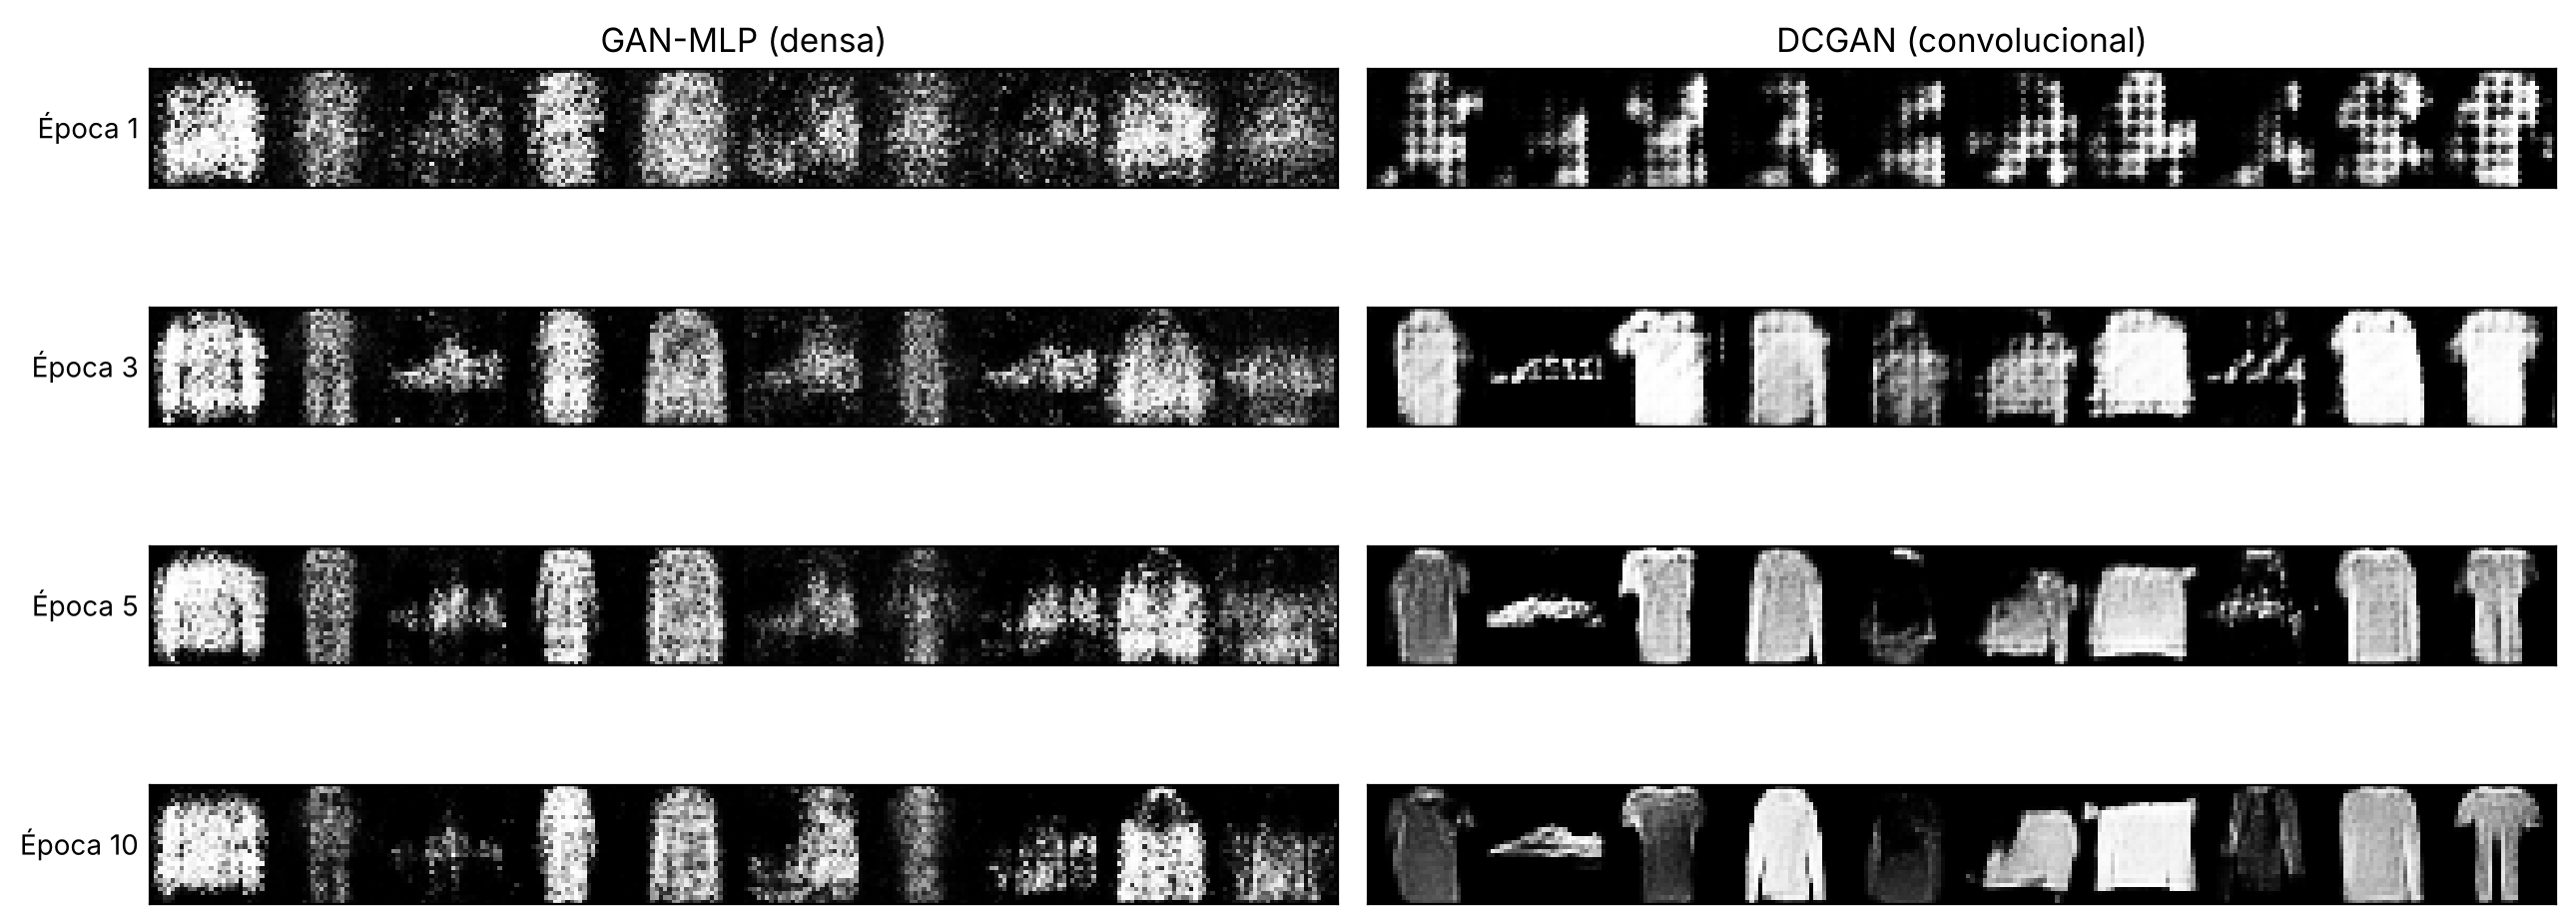

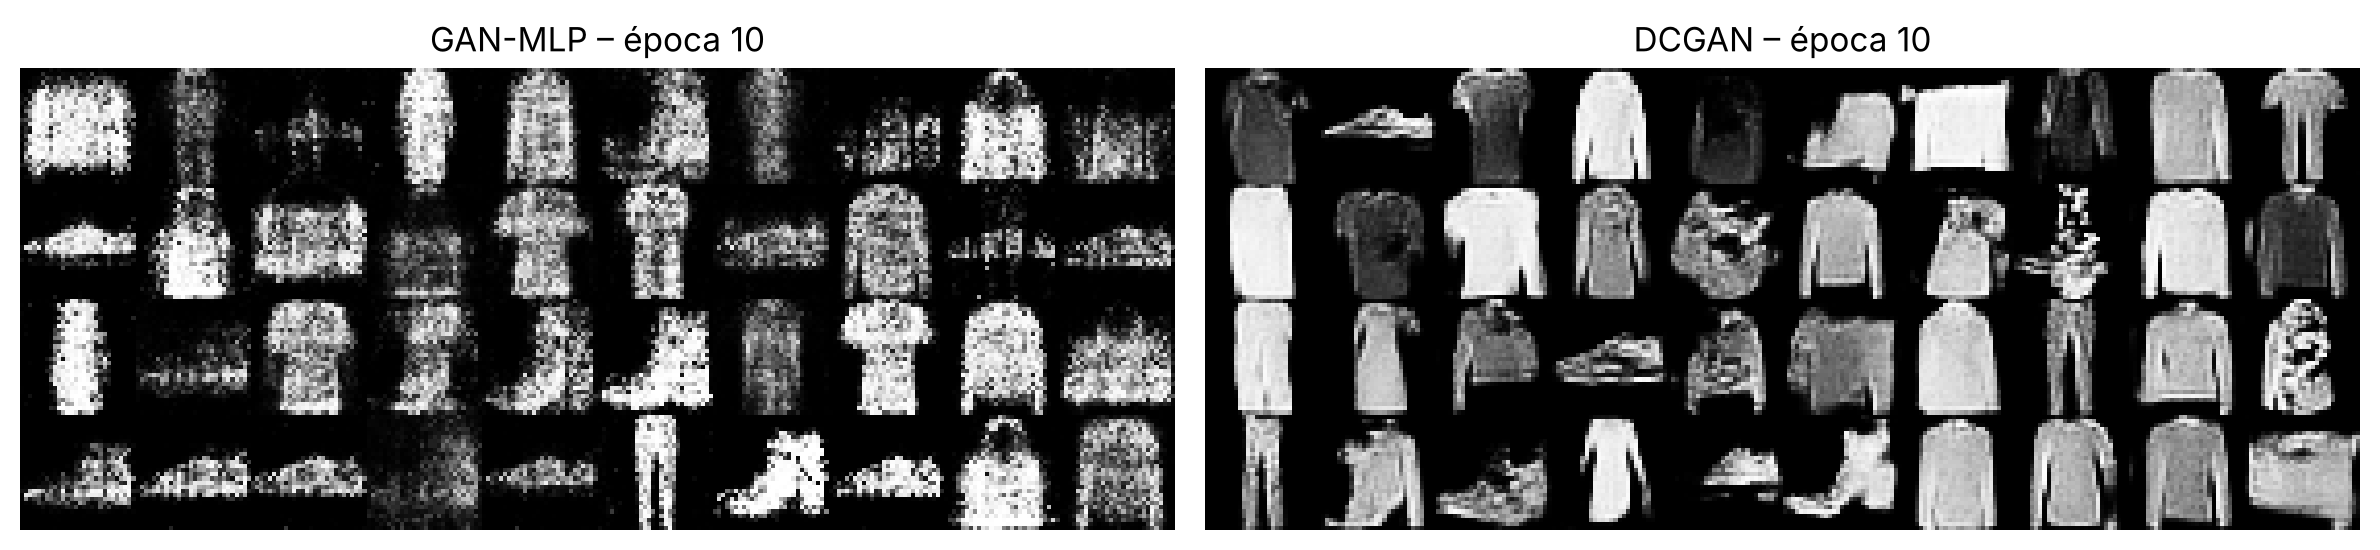

In [8]:
def fila(imgs, n=10): return np.concatenate([imgs[i, :, :, 0] for i in range(n)], 1)
eps = sorted(snaps_dc)
fig, ax = plt.subplots(len(eps), 2, figsize=(13, 1.35 * len(eps)))
for i, e in enumerate(eps):
    ax[i, 0].imshow(fila(snaps_mlp[e]), cmap='gray'); ax[i, 1].imshow(fila(snaps_dc[e]), cmap='gray')
    ax[i, 0].set_ylabel(f'Época {e}', rotation=0, ha='right', va='center')
    for a in ax[i]: a.set_xticks([]); a.set_yticks([])
ax[0, 0].set_title('GAN-MLP (densa)'); ax[0, 1].set_title('DCGAN (convolucional)')
plt.tight_layout(); plt.savefig('fig/f_evolucion.png', dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, s, t in [(ax[0], snaps_mlp[EPOCHS], 'GAN-MLP'), (ax[1], snaps_dc[EPOCHS], 'DCGAN')]:
    g = np.concatenate([fila(s[r*10:(r+1)*10]) for r in range(4)], 0)
    a.imshow(g, cmap='gray'); a.set_title(f'{t} – época {EPOCHS}'); a.axis('off')
plt.tight_layout(); plt.savefig('fig/f_final.png', dpi=200); plt.show()

## 6. Evaluación cuantitativa
Se entrena un **clasificador CNN solo con imágenes reales** y se usa como “juez”:
- **Puntaje de Inception adaptado (IS):** alto si cada imagen se clasifica con seguridad (calidad) y si las clases están variadas (diversidad). Máximo teórico = 10.
- **Cobertura de clases:** cuántas de las 10 prendas aparecen y qué tan balanceadas están.
- **FID adaptado:** distancia de Fréchet entre las activaciones de la penúltima capa del clasificador para imágenes reales y generadas (menor = mejor) (Heusel et al., 2017).

In [9]:
clf = keras.Sequential([layers.Input((28, 28, 1)),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dense(128, activation='relu', name='emb'), layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')])
clf.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
clf.fit(x_train, y_train, epochs=4, batch_size=128, verbose=2)
acc_clf = clf.evaluate(x_test, y_test, verbose=0)[1]
print(f'Exactitud del clasificador en prueba real: {acc_clf:.4f}')
emb = keras.Model(clf.inputs, clf.get_layer('emb').output)

Epoch 1/4


469/469 - 7s - 15ms/step - accuracy: 0.7988 - loss: 0.5598


Epoch 2/4


469/469 - 10s - 22ms/step - accuracy: 0.8707 - loss: 0.3588


Epoch 3/4


469/469 - 10s - 22ms/step - accuracy: 0.8885 - loss: 0.3087


Epoch 4/4


469/469 - 7s - 14ms/step - accuracy: 0.9000 - loss: 0.2768


Exactitud del clasificador en prueba real: 0.8966


In [10]:
from scipy import linalg
def inception_score(p):
    py = p.mean(0, keepdims=True)
    return float(np.exp(np.mean(np.sum(p * (np.log(p + 1e-12) - np.log(py + 1e-12)), 1))))
def fid(a, b):
    m1, m2 = a.mean(0), b.mean(0); s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    cs = linalg.sqrtm(s1 @ s2).real
    return float(((m1 - m2)**2).sum() + np.trace(s1 + s2 - 2*cs))
N = 5000
feat_ref = emb.predict(x_test[:N], verbose=0)
res = {}
def evaluar(nombre, imgs):
    p = clf.predict(imgs, verbose=0); cls = p.argmax(1); dist = np.bincount(cls, minlength=10) / len(cls)
    ent = float(-(dist[dist>0] * np.log(dist[dist>0])).sum() / np.log(10))
    res[nombre] = dict(IS=inception_score(p), FID=fid(emb.predict(imgs, verbose=0), feat_ref),
                       confianza=float(p.max(1).mean()), clases_cubiertas=int((dist >= 0.01).sum()),
                       entropia_norm=ent, dist=dist.round(4).tolist())
evaluar('Reales (train)', x_train[:N])
evaluar('GAN-MLP', G1.predict(tf.random.normal((N, ZDIM), seed=1), verbose=0))
evaluar('DCGAN',   G2.predict(tf.random.normal((N, ZDIM), seed=1), verbose=0))
res['_meta'] = dict(acc_clf=acc_clf, epochs=EPOCHS,
    params={'G_MLP': G1.count_params(), 'D_MLP': D1.count_params(), 'G_DCGAN': G2.count_params(), 'D_DCGAN': D2.count_params()},
    tiempo={'GAN-MLP': hist_mlp[-1, 5], 'DCGAN': hist_dc[-1, 5]},
    hist_mlp=hist_mlp.round(4).tolist(), hist_dc=hist_dc.round(4).tolist())
json.dump(res, open('resultados.json', 'w'), indent=1, default=float)
for k in ['Reales (train)', 'GAN-MLP', 'DCGAN']:
    r = res[k]; print(f"{k:15s} IS={r['IS']:.2f}  FID={r['FID']:.2f}  confianza={r['confianza']:.3f}  clases={r['clases_cubiertas']}/10  entropía={r['entropia_norm']:.3f}")

/tmp/ipykernel_245/141052823.py:7: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cs = linalg.sqrtm(s1 @ s2).real


Reales (train)  IS=7.68  FID=0.41  confianza=0.903  clases=10/10  entropía=0.999
GAN-MLP         IS=4.17  FID=29.41  confianza=0.703  clases=10/10  entropía=0.926
DCGAN           IS=5.32  FID=8.45  confianza=0.772  clases=10/10  entropía=0.985


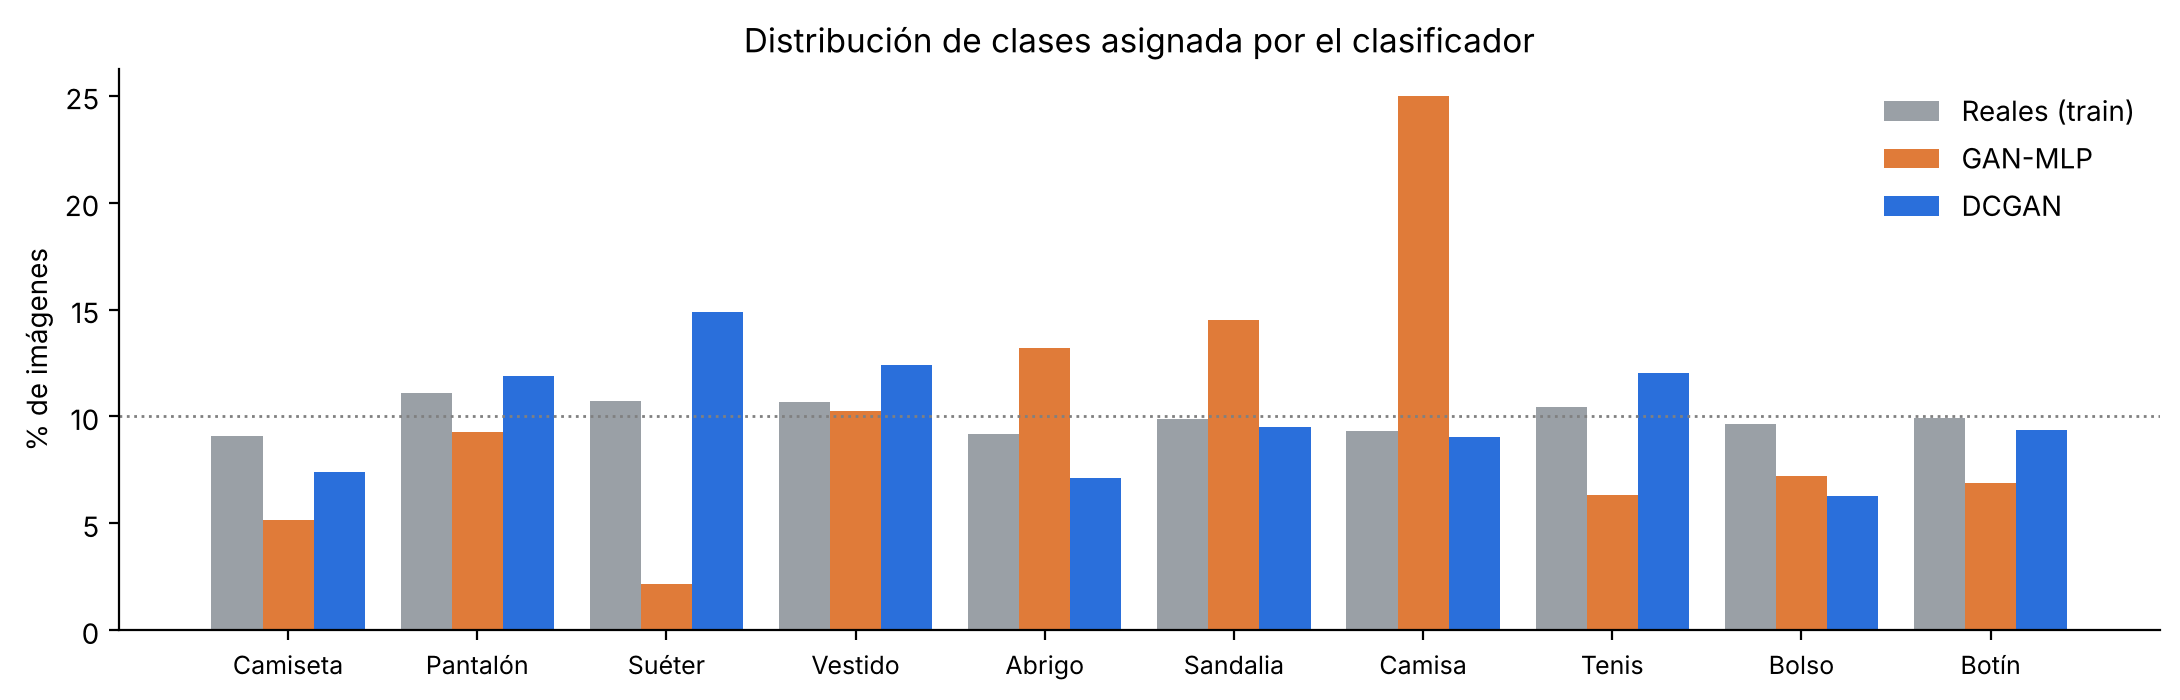

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.6)); w = 0.27; x = np.arange(10)
for i, (k, c) in enumerate([('Reales (train)', '#9aa0a6'), ('GAN-MLP', '#e07b39'), ('DCGAN', '#2a6fdb')]):
    ax.bar(x + (i-1)*w, np.array(res[k]['dist'])*100, w, color=c, label=k)
ax.axhline(10, color='gray', ls=':', lw=1); ax.set_xticks(x, CLASES, fontsize=9); ax.set_ylabel('% de imágenes')
ax.set_title('Distribución de clases asignada por el clasificador'); ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig/f_clases.png', dpi=200); plt.show()

## 7. Exploración del espacio latente (DCGAN)
Interpolación lineal entre dos vectores de ruido: si el generador aprendió una representación continua, las imágenes deben transformarse suavemente.

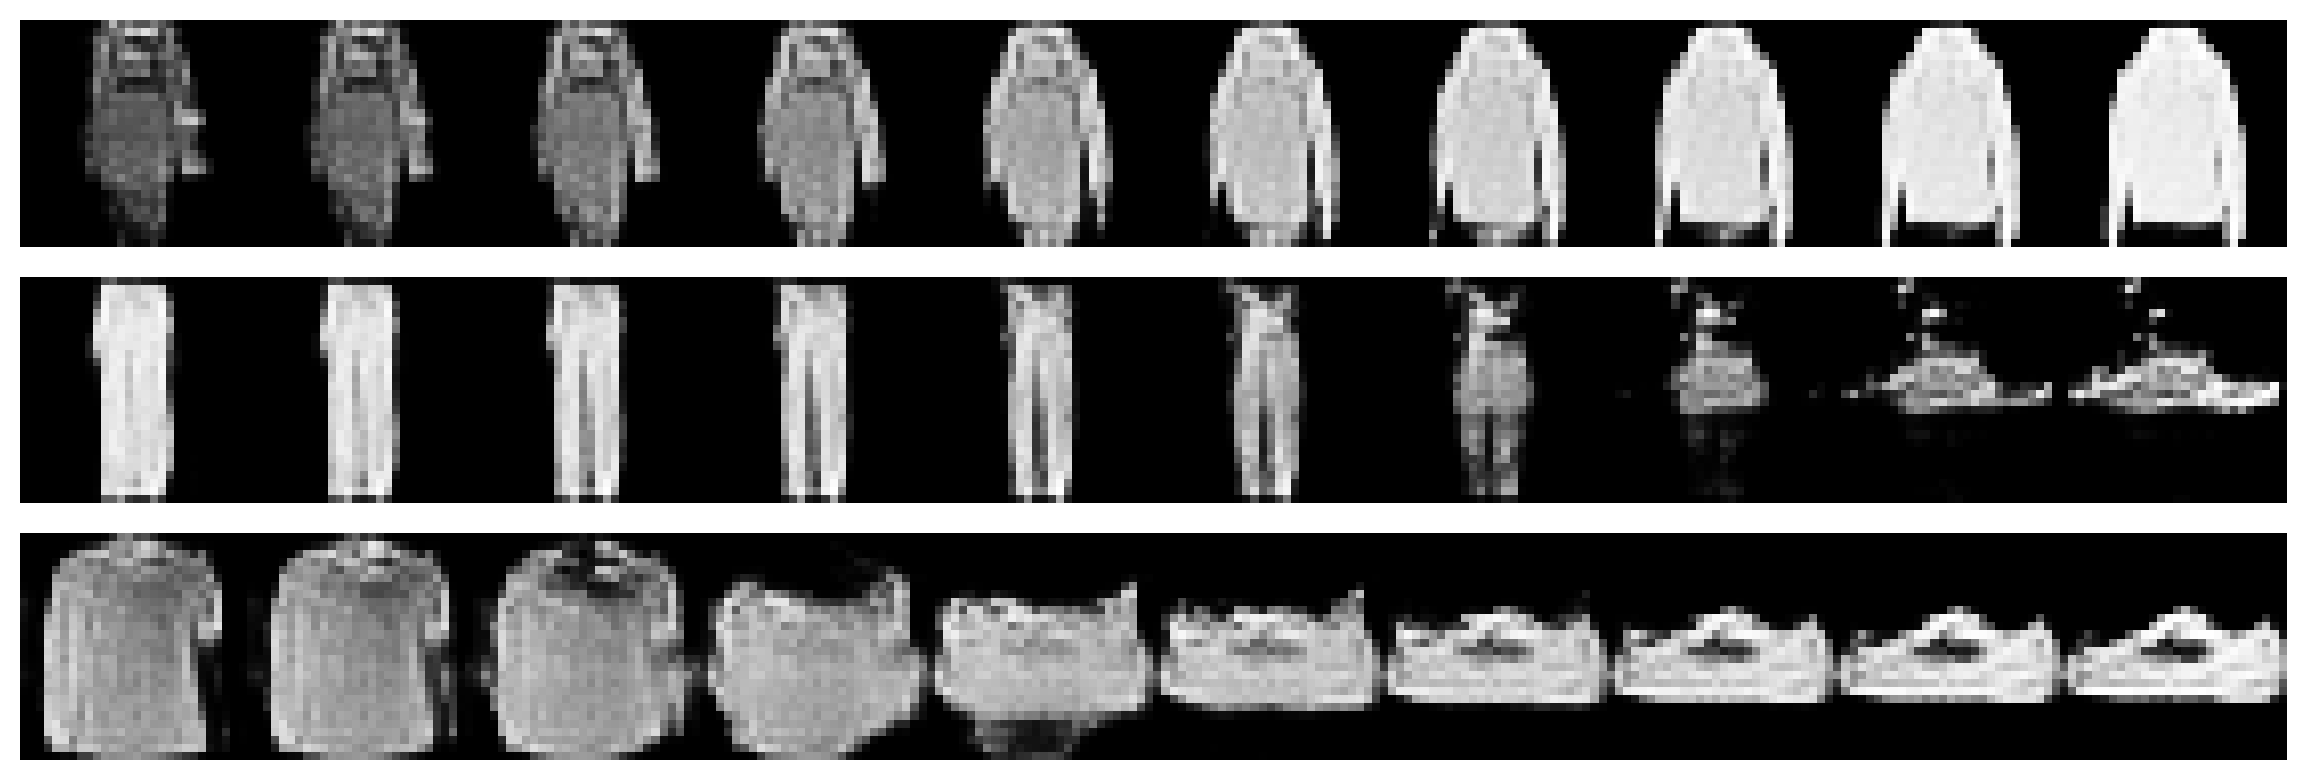

In [12]:
za, zb = tf.random.normal((3, ZDIM), seed=11), tf.random.normal((3, ZDIM), seed=22)
al = np.linspace(0, 1, 10)
fig, ax = plt.subplots(3, 1, figsize=(12, 4))
for r in range(3):
    zz = tf.stack([(1-a)*za[r] + a*zb[r] for a in al])
    ax[r].imshow(fila(G2(zz, training=False).numpy()), cmap='gray'); ax[r].axis('off')
plt.tight_layout(); plt.savefig('fig/f_interp.png', dpi=200); plt.show()

## 8. Conclusión breve
Ver el informe en Word para el análisis completo. En resumen: ambas redes aprenden a generar prendas a partir de ruido, pero la DCGAN, al aprovechar la estructura espacial de la imagen con convoluciones, produce imágenes más nítidas y obtiene mejores métricas (IS más alto y FID más bajo) que la GAN densa con el mismo número de épocas.